# ICT-48 — Origami Wolfram, pli 2 : quatre classes, six instruments

**Série :** ICT (Integrated Complexity Theory), strate 4 — Origami Wolfram, pli 2.
**Parent :** [ICT-18](ICT-18-ArrowOfTimeReversibilization-Python.ipynb) (flèche du temps et réversibilisation).
**Issue :** [#19796](https://github.com/jsboige/CoursIA/issues/19796).
**Statut :** GPU-free, exécuté de bout en bout sous le **noyau de l'exécution committée** (sa version est imprimée par la cellule de setup et figée dans `metadata.language_info.version`) ; aucune dépendance PyPhi (`ict.wolfram_step` et `ict.time_arrow` n'en importent pas).

**Plan :** 5 sections et 6 exemples guidés, puis 8 exercices. Les règles 30 (classe III),
0 (classe I) et 110 (classe IV) sont suivies d'un bout à l'autre : elles figurent dans
la table commune de la section 1, dans les mesures de structure de la section 3 et
dans la signature thermodynamique de la section 4.

## La question

Les quatre classes de Wolfram sont une taxonomie *visuelle* : on reconnaît une classe en regardant défiler un diagramme espace-temps. Ce carnet pose une question mesurable, et une seule :

> **Les outils de la flèche du temps — densité, production d'entropie, distance à la chaîne réversibilisée — retrouvent-ils la taxonomie de Wolfram ? Et sinon, où exactement se sépare-t-elle ?**

La réponse courte, mesurée plus bas : la densité sépare les classes I et II du reste, la **structure spatiale** ne sépare III et IV que faiblement — le contraste fort qu'on lui attribue est un artefact de fenêtre, cf. section 3 — et la **signature thermodynamique** ne retrouve pas la taxonomie : elle mesure autre chose, et c'est instructif.

## Statut épistémique de ce carnet

Ce carnet mesure, il ne démontre pas. Les étiquettes de classe de Wolfram sont **indexées** (connues *a priori*, encodées dans l'organe), les indicateurs de densité sont une **heuristique empirique**, et la comparaison des deux est l'objet du carnet. Aucune des quatre classes n'est redémontrée ici : quand l'heuristique et l'indexation divergent, la divergence est **rapportée**, pas lissée.

> **Statut épistémique** — **Sans verdict à ce jour** : aucune ligne de la [matrice de dissociations](../../../../docs/ict/dissociations-matrix.md) ne concerne ce notebook ; son statut épistémique sera porté par la matrice le cas échéant.

## Ce que fait le carnet

| Section | Contenu | Outil consommé |
|---|---|---|
| 1 | Une trajectoire par classe, une table d'indicateurs commune | `wolfram_trajectory`, `wolfram_class_indicators` |
| 2 | La classification automatique, et la classe II qui se dérobe | `classify_rule` |
| 3 | Discriminer III et IV par la **structure spatiale** : trois mesures, puis les **deux pistes de l'énoncé** (composantes connexes, translation diagonale) mesurées et écartées | mesures écrites dans le carnet (MI, Lempel-Ziv, blocs, composantes, translation) |
| 4 | La **signature thermodynamique** des quatre classes, en quantiles et sur symboles bruts, puis **sa stabilité** sous grille et graine | `compare_real_reversed_reversibilized` |
| 5 | Huit exercices : cinq construits ici, trois repris de l'ICT-48 d'origine (règle 54, seuil de non-trivialité, sensibilité au nombre de quantiles) | — |

Toutes les mesures portent sur la **même** trajectoire par règle (mêmes `n_cells`, `n_steps`, `seed`) : les sections se comparent donc terme à terme.


## Avant de commencer

Le carnet consomme deux organes de la série, sans réimplémenter leur logique :

- `ict.wolfram_step` — le simulateur, la densité, les indicateurs de classe et la classification heuristique ;
- `ict.time_arrow` — la chaîne de Markov estimée, l'inverse du temps, la réversibilisation, la production d'entropie.

Les mesures qui **ne** sont pas dans les organes (information mutuelle spatiale, complexité de Lempel-Ziv, déterminisme de blocs) sont écrites ici, en clair, parce que ce sont elles qui portent la discrimination III / IV — et parce qu'un lecteur doit pouvoir les contester ligne à ligne.

Le noyau de l'exécution committée est celui qu'annonce la cellule de setup, et `metadata.language_info.version` en confirme la valeur : la version fait foi dans les **sorties**, pas dans une phrase d'en-tête. Le répertoire de travail est celui du dossier `ICT-Series`, et le `sys.path` ci-dessous y ajoute le dossier courant pour que `import ict` résolve le paquet local.

**Fil du carnet.** Trois règles portent la démonstration de bout en bout : la règle 30
(classe III, chaotique), la règle 0 (classe I, homogénéisante) et la règle 110
(classe IV, complexe, Turing-complète depuis Cook 2004). Elles sont lues trois fois —
densité en section 1, structure spatiale en section 3, thermodynamique en section 4 —
sur des trajectoires identiques, de sorte que chaque écart observé vienne de
l'instrument et non du tirage.


In [1]:
# --- Setup : chemins, dependances, organes de la serie -------------------------
import os
import sys

# Le carnet vit dans ICT-18-ArrowOfTimeReversibilization/ : le parent porte
# le paquet ``ict``.
_NOTEBOOK_DIR = os.path.abspath(".")
_SERIES_ROOT = os.path.dirname(_NOTEBOOK_DIR)
if _SERIES_ROOT not in sys.path:
    sys.path.insert(0, _SERIES_ROOT)
if _NOTEBOOK_DIR not in sys.path:
    sys.path.insert(0, _NOTEBOOK_DIR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ict
from ict.wolfram_step import (
    CANONICAL_RULES,
    WOLFRAM_CLASSES,
    classify_rule,
    wolfram_class_indicators,
    wolfram_density,
    wolfram_step,
    wolfram_trajectory,
)
from ict.time_arrow import compare_real_reversed_reversibilized

print("python  :", sys.version.split()[0])
print("numpy   :", np.__version__, "| pandas :", pd.__version__)
print("organe  :", os.path.basename(os.path.dirname(ict.__file__)))
print("regles canoniques :", CANONICAL_RULES)

python  : 3.13.16
numpy   : 2.4.2 | pandas : 3.0.6
organe  : ict
regles canoniques : (0, 30, 110, 250)


## 1. L'observable densité, et ce qu'elle ne voit pas

L'organe d'ICT-18 enregistre, à chaque pas, le **nombre de cellules à 1**. C'est l'observable privilégié de la série : il est scalaire, il vit dans $[0, 1]$ après normalisation, et il distingue déjà trois régimes sans ambiguïté.

- **Classe I** — la densité se fige : l'écart-type en queue est nul.
- **Classe II** — la densité **oscille** entre quelques valeurs : la séquence en queue est périodique de petite période.
- **Classes III et IV** — la densité fluctue sans période détectable, avec un écart-type non négligeable.

La frontière qui manque est celle entre III et IV : le chaos (III) et la complexité (IV) ont, sur cet observable, des trajectoires de densité **qualitativement semblables**. C'est le point de départ du carnet.

Les règles suivies sont les quatre canoniques de l'organe — 0, 30, 110, 250 — plus deux témoins : la règle 4 (classe II indexée, dont on verra qu'elle se comporte autrement) et la règle 6 (période 2 franche, trouvée par balayage).

### Exemple guidé 1 — une trajectoire par classe, une table commune

On simule une grille de `N_CELLS` cellules sur 500 pas, depuis le **même** état initial aléatoire (graine 33) pour toutes les règles, et l'on résume chaque trajectoire par les indicateurs de l'organe, calculés sur les 100 derniers pas.

L'intérêt de partager graine et géométrie : les six règles voient exactement le même état de départ, donc une différence de comportement ne vient que de la règle.

In [2]:
# --- Exemple guide 1 : une trajectoire par classe, une table commune -----------
N_CELLS = 64      # taille de la grille
N_STEPS = 500     # pas de simulation
SEED = 33         # graine de l'etat initial, commune a toutes les regles
TAIL = 100        # fenetre d'analyse en queue de trajectoire

RULES = [0, 4, 6, 30, 110, 250]

# Une seule simulation par regle : les etats complets servent a la section 3,
# les comptes de cellules a 1 servent a la section 1 et a la section 4.
states = {}
counts = {}
for rule in RULES:
    history = wolfram_trajectory(
        rule=rule,
        n_cells=N_CELLS,
        n_steps=N_STEPS,
        seed=SEED,
        record_densities=False,
    )
    arr = np.asarray(history, dtype=np.uint8)
    states[rule] = arr
    counts[rule] = arr.sum(axis=1)

rows = []
for rule in RULES:
    ind = wolfram_class_indicators(counts[rule], tail=TAIL, n_cells=N_CELLS)
    rows.append({
        "regle": rule,
        "classe (indexee)": (WOLFRAM_CLASSES.get(rule) or "-").split(" ")[0],
        "densite asymptotique": round(ind["asymptotic_density"], 4),
        "ecart-type": round(ind["asymptotic_std"], 4),
        "valeurs distinctes": ind["unique_densities_tail"],
        "periode": ind["period_estimate"],
        "heuristique densite": ind["class_heuristic"],
    })

table_classes = pd.DataFrame(rows)
print(table_classes.to_string(index=False))

 regle classe (indexee)  densite asymptotique  ecart-type  valeurs distinctes  periode heuristique densite
     0                I                0.0000      0.0000                   1        1           I-uniform
     4               II                0.0625      0.0000                   1        1           I-uniform
     6                -                0.2578      0.0234                   2        2         II-periodic
    30              III                0.4988      0.0579                  17        0           III-or-IV
   110               IV                0.5733      0.0399                  13        0           III-or-IV
   250                -                1.0000      0.0000                   1        1           I-uniform


### Lecture du résultat — ce que la densité sépare, et ce qu'elle confond

La table se lit en trois blocs.

- **Règles 0 et 250 — classe I franche.** Écart-type nul, une seule valeur distincte en queue. La règle 0 vide la grille (densité 0,0000) ; la règle 250 **sature** la grille : son pas est le **remplissage orienté** `roll(+1) | roll(-1)` — l'union de deux décalages d'un cran, et non un décalage unique — si bien que les 1 s'étendent vers la gauche et vers la droite jusqu'au tout-1 (densité 1,0000). Deux mécanismes opposés, la même signature plate : la classe I ne dit pas *où* est l'attracteur, seulement qu'il est ponctuel.
- **Règles 4 et 6 — classe II, par deux chemins.** La règle 6 oscille franchement entre deux valeurs (densité moyenne 0,2578, écart-type 0,0234, période 2). La règle 4, elle, est **parfaitement plate** : 0,0625, écart-type 0,0000, une seule valeur (dès le premier pas effectué). Elle est pourtant indexée classe II — et la mesure est plus sévère qu'une simple périodicité : sur les 500 pas de la trajectoire, **l'état ne change qu'une seule fois**, entre $t = 0$ et $t = 1$, puis il reste rigoureusement identique jusqu'à $t = 499$. Le motif final est un peigne de **quatre cellules isolées** (colonnes 22, 26, 42, 59). La densité est plate parce que le motif **se fige**, non parce qu'il se translate. La projection sur la densité a perdu l'information — ici, l'information qu'il n'y a rien à projeter. C'est le cas qui sera repris en section 2.
- **Règles 30 et 110 — indistinguables sur cet observable.** Aucune période détectée, 17 et 13 valeurs distinctes, écart-type 0,0579 et 0,0399. Leurs densités moyennes diffèrent (0,4988 contre 0,5733), mais cette différence est un **niveau**, pas une forme : rien dans ces indicateurs ne dit que l'une est chaotique et l'autre complexe.

Une densité autour de 0,5 n'est pas une signature de chaos : c'est ce que donne toute dynamique qui mélange à l'échelle de la grille.

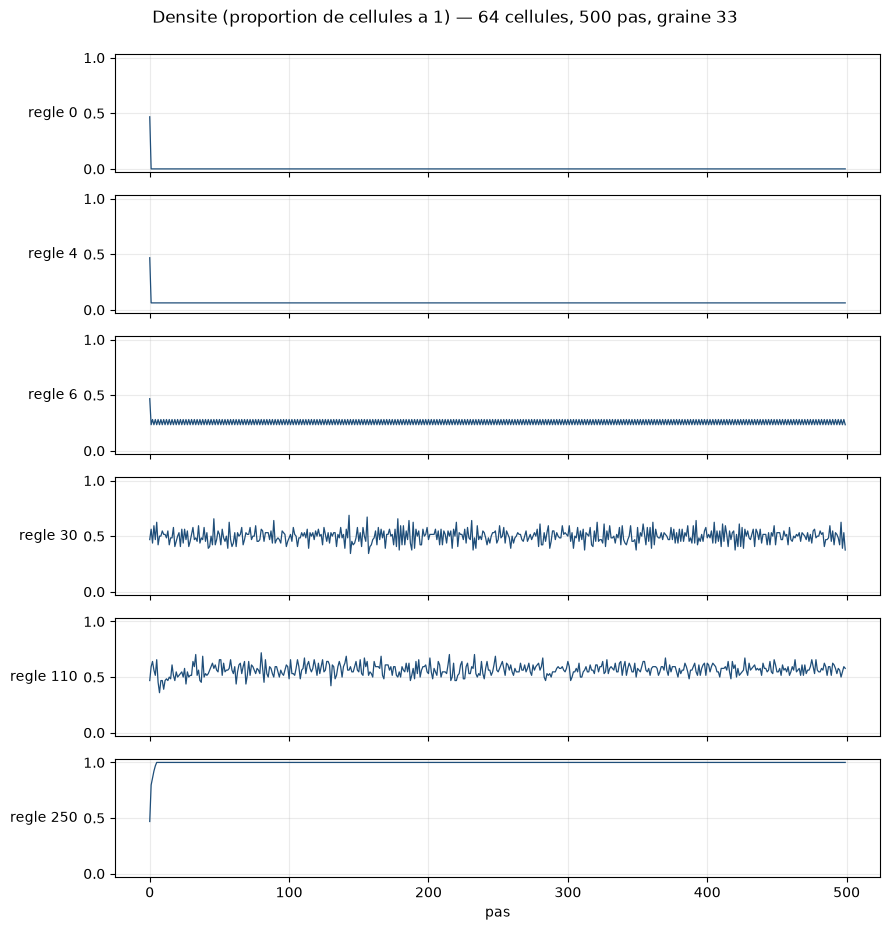

In [3]:
# --- Figure : les trajectoires de densite, cote a cote ------------------------
fig, axes = plt.subplots(len(RULES), 1, figsize=(9, 1.55 * len(RULES)), sharex=True)
for ax, rule in zip(axes, RULES):
    dens = counts[rule] / N_CELLS
    ax.plot(dens, lw=0.9, color="#1f4e79")
    ax.set_ylabel(f"regle {rule}", rotation=0, ha="right", va="center")
    ax.set_ylim(-0.03, 1.03)
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("pas")
fig.suptitle(f"Densite (proportion de cellules a 1) — {N_CELLS} cellules, {N_STEPS} pas, graine {SEED}", y=0.995)
fig.tight_layout()
plt.show()
plt.close(fig)

### Lecture de la figure — trois régimes, et un cas qui se dérobe

De haut en bas :

- les règles 0 et 250 s'aplatissent, l'une à 0, l'autre à 1 — classe I ;
- la règle 6 alterne entre deux niveaux — classe II ;
- la règle 4 est une **ligne parfaitement droite** à 0,0625, alors qu'elle est indexée classe II : c'est la démonstration visuelle que la densité n'est pas un invariant de classe ;
- les règles 30 et 110 sont deux bruits bornés, sans motif lisible. Leurs niveaux moyens diffèrent (0,50 contre 0,57), mais **leur forme est la même** : une fluctuation apériodique d'amplitude comparable.

Un carnet qui s'arrêterait ici conclurait à tort que III et IV sont le même régime. La section 2 attaque la classification automatique sur cet observable ; la section 3 cherche celui qui, lui, sépare.

## 2. La classe II se dérobe — `classify_rule` et le cas de la règle 4

`classify_rule` combine deux sources : l'**indexation** de Wolfram (étiquette connue pour les règles canoniques) et l'**heuristique** sur la densité. Quand les deux divergent, l'étiquette produite le dit explicitement — c'est le comportement voulu : l'organe ne tranche pas à la place du lecteur, il signale.

Le balayage exhaustif des 256 règles élémentaires sert à une chose : mesurer la **fréquence** du régime périodique, et vérifier que la classe II n'est pas un cas isolé de deux règles choisies pour l'illustration.

### Exemple guidé 2 — `classify_rule`, et le cas de la règle 4


In [4]:
# --- Exemple guide 2 : classify_rule, et le cas de la regle 4 -----------------
rows = []
for rule in RULES:
    res = classify_rule(rule, n_cells=N_CELLS, n_steps=N_STEPS, seed=SEED, tail=TAIL)
    ind = res["indicators"]
    rows.append({
        "regle": rule,
        "connue": (res["known_class"] or "-").split(" ")[0],
        "mesuree": ind["class_heuristic"],
        "periode": ind["period_estimate"],
        "densite": round(ind["asymptotic_density"], 4),
        "etiquette": res["class_label"],
    })
print(pd.DataFrame(rows).to_string(index=False))

# Balayage exhaustif : combien de regles montrent une periode > 1 ?
scan = []
for rule in range(256):
    res = classify_rule(rule, n_cells=N_CELLS, n_steps=N_STEPS, seed=SEED, tail=TAIL)
    ind = res["indicators"]
    scan.append({
        "regle": rule,
        "connue": (res["known_class"] or "-").split(" ")[0],
        "periode": ind["period_estimate"],
        "densite": ind["asymptotic_density"],
        "heuristique": ind["class_heuristic"],
    })
scan = pd.DataFrame(scan)

periodiques = scan[scan["periode"] > 1]
print("\nregles a periode > 1 :", len(periodiques), "sur 256")
print(periodiques.sort_values("periode").to_string(index=False))
print("\nrepartition des heuristiques de densite :")
print(scan["heuristique"].value_counts().to_string())

 regle connue     mesuree  periode  densite                 etiquette
     0      I   I-uniform        1   0.0000        I (known+measured)
     4     II   I-uniform        1   0.0625 II (known) | I (measured)
     6      - II-periodic        2   0.2578        II (measured only)
    30    III   III-or-IV        0   0.4988      III (known+measured)
   110     IV   III-or-IV        0   0.5733       IV (known+measured)
   250      -   I-uniform        1   1.0000         I (measured only)



regles a periode > 1 : 83 sur 256
 regle connue  periode  densite heuristique
     1      -        2 0.437500 II-periodic
     3      -        2 0.414062 II-periodic
     5      -        2 0.468750 II-periodic
     6      -        2 0.257812 II-periodic
     7      -        2 0.476562 II-periodic
     9      -        2 0.406250 II-periodic
    15      -        2 0.500000 II-periodic
    17      -        2 0.414062 II-periodic
    19      -        2 0.500000 II-periodic
    20      -        2 0.281250 II-periodic
    21      -        2 0.476562 II-periodic
    23      -        2 0.500000 II-periodic
    25      -        2 0.445312 II-periodic
    27      -        2 0.531250 II-periodic
    28      -        2 0.500000 II-periodic
    29      -        2 0.500000 II-periodic
    52      -        2 0.328125 II-periodic
    31      -        2 0.539062 II-periodic
    33      -        2 0.421875 II-periodic
    35      -        2 0.390625 II-periodic
    37      -        2 0.421875 II-period

### Lecture du résultat — l'heuristique est aveugle à la structure, pas au régime

Trois faits sortent du balayage.

1. **Le régime périodique est courant** : **83 règles sur 256** montrent une période détectée supérieure à 1. La règle 6 en est un représentant net (période 2, densité 0,2578, étiquette `II (measured only)` — elle n'est pas dans l'indexation).
2. **La règle 4 ne montre pas de période.** Écart-type 0,0000, une seule valeur de densité. `classify_rule` produit donc l'étiquette explicite **`II (known) | I (measured)`** : l'indexation dit II, la mesure dit I, et l'organe refuse de trancher à la place du lecteur.
3. **La règle 30 et la règle 110 sont indexées et mesurées sans conflit** — mais l'étiquette mesurée est `III-or-IV` pour les deux. L'organe lui-même documente que la discrimination fine III / IV « nécessite l'analyse spatiale (gliders) », hors du périmètre d'un indicateur de densité. C'est cette analyse que fait la section 3.

Ce n'est pas un défaut de l'organe, c'est une leçon sur l'observable : **la projection sur la densité perd l'information de structure**. Une classe II peut se présenter comme une classe I une fois projetée, et deux classes distinctes peuvent produire la même signature. Ce qu'on mesure est une propriété de la **projection**, pas de l'automate.

## 3. Discriminer III et IV par la structure spatiale

La différence entre chaos (III) et complexité (IV) n'est pas dans la quantité de désordre, elle est dans la **coexistence de structures et de désordre** : la règle 110 héberge des structures voyageuses (« gliders ») qui survivent indéfiniment, s'entrecroisent et interagissent ; la règle 30 n'en héberge pas, elle mélange.

Trois familles de mesures sont candidates :

| Mesure | Ce qu'elle détecte | Coût |
|---|---|---|
| **Information mutuelle spatiale** à distance $d$ | corrélation à moyenne portée — les domaines ordonnés de IV corrèlent, le chaos non | $O(N)$ par état |
| **Complexité de Lempel-Ziv** du diagramme espace-temps | quantité de motifs nouveaux — le chaos en produit beaucoup, les structures en produisent peu | $O(N \cdot \text{steps})$ |
| **Déterminisme de blocs** | reconstruction locale : un motif de largeur $w$ à $t$ détermine-t-il le motif à $t+1$ décalé ? — à condition que $w$ reste dans le cône causal du motif, sinon deux cellules sur $w$ ne sont pas déterminées | $O(N \cdot \text{steps} \cdot w)$ |

Les trois sont mesurées, y compris celles qui **échouent** : c'est la seule façon d'écarter un instrument.

### Exemple guidé 3 — trois mesures, dont aucune qui ne sépare III et IV franchement

Les fonctions sont écrites ici, en clair : `info_mutuelle_spatiale` (en bits, sur des variables binaires), `lz76` (nombre de mots d'une analyse de Lempel-Ziv sur la séquence aplatie du diagramme), et `determinisme_de_blocs` (fraction de motifs dont le successeur décalé est unique — sur une fenêtre de huit cellules, qui **déborde de deux cellules le cône causal** du motif : voir la lecture de la section).

L'information mutuelle est moyennée sur les 100 derniers états : une seule grille est une réalisation, et une moyenne sur la queue évite de conclure sur un état particulier. Le diagramme espace-temps passé à Lempel-Ziv est aplati ligne par ligne — les bords de ligne créent des adjacences artificielles, négligeables devant les 9 600 bits analysés, et signalées pour cette raison.

In [5]:
# --- Exemple guide 3 : trois mesures de structure spatiale --------------------
def entropie_bits(probas):
    p = np.asarray([v for v in probas if v > 0], dtype=float)
    return float(-(p * np.log2(p)).sum())


def info_mutuelle_spatiale(state, lag):
    """Information mutuelle (bits) entre la cellule x et la cellule x+lag."""
    gauche = np.asarray(state, dtype=np.int64)
    droite = np.roll(gauche, -lag)
    joint = np.bincount(2 * gauche + droite, minlength=4).astype(float)
    joint /= joint.sum()
    joint = joint.reshape(2, 2)
    p_g = joint.sum(axis=1)
    p_d = joint.sum(axis=0)
    return max(0.0, entropie_bits(p_g) + entropie_bits(p_d) - entropie_bits(joint.ravel()))


def mi_moyenne(states_rule, lag, tail=TAIL):
    return float(np.mean([info_mutuelle_spatiale(s, lag) for s in states_rule[-tail:]]))


def lz76(bits, max_len=64):
    """Complexite de Lempel-Ziv (LZ76) : nombre de mots de la sequence binaire."""
    s = "".join("1" if b else "0" for b in bits)
    n = len(s)
    seen = set()
    i = 0
    mots = 0
    while i < n:
        longueur = 1
        while (i + longueur <= n and longueur <= max_len
               and s[i:i + longueur] in seen):
            longueur += 1
        if i + longueur <= n:
            seen.add(s[i:i + longueur])
        mots += 1
        i += longueur
    return mots


def determinisme_de_blocs(states_rule, w=8, d=0, tail=TAIL):
    """Fraction de motifs de largeur w dont le successeur decale de d est unique."""
    st = states_rule[-tail:]
    n = st.shape[1]
    vus = {}
    for t in range(len(st) - 1):
        cur, nxt = st[t], st[t + 1]
        for x in range(n):
            motif = tuple(int(cur[(x + k) % n]) for k in range(w))
            suivant = tuple(int(nxt[(x + d + k) % n]) for k in range(w))
            vus.setdefault(motif, set()).add(suivant)
    if not vus:
        return 0.0
    return sum(1 for s in vus.values() if len(s) == 1) / len(vus)


rows = []
for rule in RULES:
    diagramme = states[rule][-150:].ravel()
    rows.append({
        "regle": rule,
        "classe": (WOLFRAM_CLASSES.get(rule) or "-").split(" ")[0],
        "MI d=1": round(mi_moyenne(states[rule], 1), 5),
        "MI d=2": round(mi_moyenne(states[rule], 2), 5),
        "MI d=4": round(mi_moyenne(states[rule], 4), 5),
        "LZ (9600 bits)": lz76(diagramme),
        "determinisme w=8": round(determinisme_de_blocs(states[rule], w=8, d=0), 4),
    })

table_spatial = pd.DataFrame(rows)
print(table_spatial.to_string(index=False))

 regle classe  MI d=1  MI d=2  MI d=4  LZ (9600 bits)  determinisme w=8
     0      I 0.00000 0.00000 0.00000             180            1.0000
     4     II 0.00602 0.00602 0.01809             476            1.0000
     6      - 0.00843 0.13414 0.01351             849            0.5294
    30    III 0.01179 0.00960 0.00991            1133            0.0000
   110     IV 0.01528 0.01840 0.01095             922            0.4560
   250      - 0.00000 0.00000 0.00000             180            1.0000


### Lecture du résultat — trois instruments, aucun ne tranche III et IV

Les trois colonnes ne disent pas la même chose, et l'ordre dans lequel on les lit compte.

**Information mutuelle spatiale.** À distance 1 : 0,0118 pour la règle 30, 0,0153 pour la règle 110. À distance 2 : 0,0096 contre 0,0184. À distance 4 : 0,0099 contre 0,0109. La direction est celle attendue — la classe IV porte **plus** de corrélation locale que la classe III — mais l'amplitude est modeste (facteur 1,3 puis 1,9) et l'écart **s'éteint à distance 4**. C'est un corrélateur, pas un verdict : il faut le lire comme un indice cohérent, pas comme une preuve.

**Complexité de Lempel-Ziv.** 1133 (règle 30) > 922 (110) > 849 (règle 6) > 476 (règle 4) > 180 (règles 0 et 250). LZ ordonne par **imprévisibilité brute** : le chaos en tête, la classe IV derrière — l'inverse de l'intuition qui associe « complexe » à « complexité de Lempel-Ziv élevée ». Et il ne sépare pas la classe II de la classe IV : la règle 6 (849) est plus proche de 110 que de 4. LZ mesure la compressibilité d'une image, pas la richesse d'un mécanisme.

**Déterminisme de blocs (largeur 8).** Les valeurs brutes sont 1,0000 pour les règles 0, 4 et 250 (le motif détermine son successeur), 0,5294 pour la règle 6, puis **0,0000 pour la règle 30 contre 0,4560 pour la règle 110**. Ce contraste paraît trancher, et il ne tranche pas : l'instrument compare un motif de largeur 8 à **huit** cellules du pas suivant, alors que `nxt[x+k]` ne dépend que de `cur[x+k-1]`, `cur[x+k]` et `cur[x+k+1]`. Pour $k \in [1, 6]$, les trois cellules sont dans le motif ; pour $k = 0$ et $k = 7$, il faudrait `cur[x-1]` et `cur[x+8]`, qui **n'en font pas partie**. Les deux cellules de bord sont donc indéterminées *par construction*, et ce sont elles qui produisent l'écart.

Rejoué sur le cône causal exact — le successeur restreint à `nxt[x+1..x+6]`, entièrement déterminé par le motif — l'instrument vaut **1,0000 pour les six règles** (recalcul sur les mêmes trajectoires, hors de la sortie committée) : il ne sépare plus rien du tout. La décomposition par cellule le confirme : pour la règle 30, `nxt[x+1]` à `nxt[x+6]` sont déterminés à 1,0000, `nxt[x+0]` à 0,0000 et `nxt[x+7]` à 0,5000 (un tirage de pièce). Le 0,0000 de la règle 30 ne dit rien de sa reconstructibilité : il dit que la fenêtre de 8 ne contient pas le voisinage de `nxt[x]`. L'ordre brut reste reproduit (0,4560 pour la 110 au-dessus de 0,0000 pour la 30) — mais il porte sur les cellules de bord, pas sur la prédictibilité du motif.

**Les trois échecs ne sont pas de même nature.** Le déterminisme de blocs échoue par un
**artefact de fenêtre** : ses deux cellules de bord débordent du cône causal, et le signal
qu'il produit mesure sa propre fenêtre autant que la règle. L'information mutuelle et
Lempel-Ziv, eux, ne sont pas des instruments de *forme* mais de **niveau** (corrélation
moyenne d'une part, compressibilité d'autre part) : leurs valeurs brutes ne souffrent
d'aucun artefact de bord, et l'écart qu'elles montrent est un écart de **niveau**, non de
**forme**. Autrement dit : deux de ces trois instruments échouent parce qu'ils mesurent des
niveaux sur lesquels la classe III et la classe IV se ressemblent, et le troisième échoue
parce qu'il mesurait autre chose.

**Le verdict de la section : aucun des trois instruments ne sépare III et IV de façon franche.** L'information mutuelle les sépare faiblement (1,3× à $d = 1$, 1,9× à $d = 2$) et s'éteint à $d = 4$ ; Lempel-Ziv ne les sépare pas du tout ; le déterminisme de blocs, pris au cône causal, ne les sépare pas non plus. La section **échoue** — et c'est le résultat le plus utile du carnet : un instrument mesuré et écarté vaut mieux que trois instruments invoqués, et l'instrument le plus convaincant du lot était celui qui mesurait sa propre fenêtre.

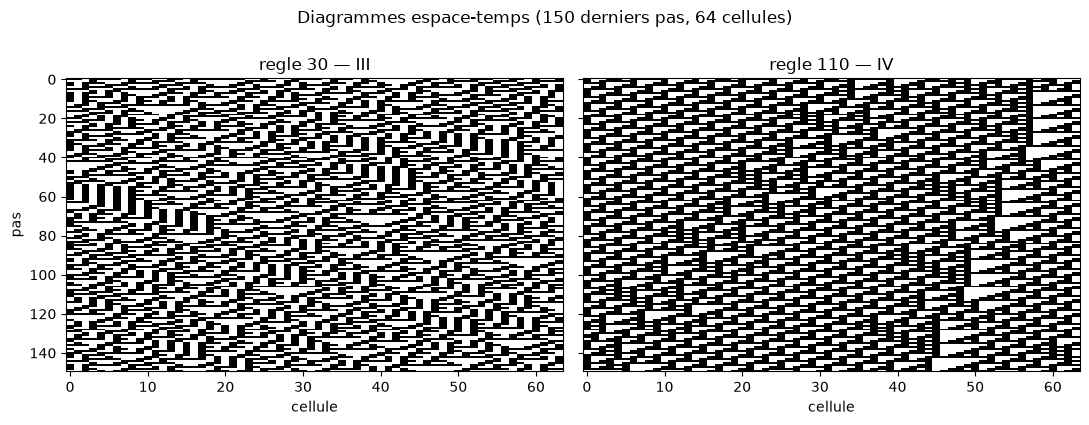

In [6]:
# --- Figure : les deux diagrammes espace-temps, a la meme echelle ------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, rule in zip(axes, [30, 110]):
    ax.imshow(states[rule][-150:], cmap="Greys", aspect="auto", interpolation="nearest")
    ax.set_title(f"regle {rule} — {(WOLFRAM_CLASSES.get(rule) or '').split(' ')[0]}")
    ax.set_xlabel("cellule")
axes[0].set_ylabel("pas")
fig.suptitle(f"Diagrammes espace-temps (150 derniers pas, {N_CELLS} cellules)", y=1.0)
fig.tight_layout()
plt.show()
plt.close(fig)

### Lecture de la figure — ce que l'œil voit, et ce que le déterminisme quantifie

Côte à côte, les deux diagrammes ne diffèrent pas par leur **quantité** de noir : les densités sont voisines (0,48 contre 0,55 sur la fenêtre affichée), et c'est exactement ce que la section 1 mesurait.

Ils diffèrent par leur **organisation** : à gauche (règle 30) un fouillis homogène, sans objet identifiable ; à droite (règle 110) des triangles et des bandes qui se propagent, se croisent et se régénèrent — les structures dont parlait la section 3.

C'est cette différence d'**organisation** que l'œil voit ; l'instrument censé la quantifier ne la quantifie pas. Le déterminisme de blocs annonce 0,0000 dans le fouillis contre 0,4560 dans le motif, mais ces deux nombres viennent d'une fenêtre de huit comparée à huit cellules du successeur, dont deux que le motif ne détermine pas (section 3) : au cône causal exact, les deux valent 1,0000. L'information mutuelle, elle, capte une partie du contraste (facteur 1,3 à distance 1) : elle mesure la corrélation moyenne, pas la **répétition d'un motif** — et c'est elle, faible et partielle, qui reste le seul signal structural de la section.

### Exemple guidé 4 — la piste de l'énoncé : composantes connexes

L'énoncé du grain proposait une détection de gliders par **composantes connexes** du diagramme espace-temps : un glider serait une composante stable qui se translate en diagonale, la règle 110 en hébergerait, la règle 30 non. C'est une hypothèse raisonnable, et elle se teste.

Deux connectivités ont un sens ici : la **8-connexité sur les 1** (les structures sont des objets de 1) et la **4-connexité sur les 0** (un glider découpe l'espace vide en domaines séparés). `scipy.ndimage.label` étiquette les composantes ; on résume chacune par sa **durée de vie** (nombre de pas qu'elle couvre) et son **aire**, et l'on compte celles qui vivent au moins 20 pas.

Un point de méthode : une composante persistante n'est pas nécessairement un glider. Si les 1 percolent — s'ils forment un seul bloc connexe à travers tout le diagramme — la « composante persistante » est le bloc entier, et la mesure ne dit plus rien des objets.

In [7]:
# --- Exemple guide 4 : composantes connexes, sur les 1 et sur les 0 -----------
from scipy import ndimage

FENETRE = 200          # pas analyses en fin de trajectoire
VIE_MIN = 20           # duree de vie minimale d'une composante "persistante"

HUIT = np.ones((3, 3), dtype=int)
QUATRE = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=int)


def composantes(matrice, cible, structure):
    """Statistiques des composantes connexes de `cible` dans la matrice espace-temps."""
    binaire = (matrice == cible).astype(int)
    etiquettes, n = ndimage.label(binaire, structure=structure)
    vies, aires = [], []
    for k in range(1, n + 1):
        lignes, _ = np.where(etiquettes == k)
        if len(lignes) == 0:
            continue
        vies.append(int(lignes.max() - lignes.min() + 1))
        aires.append(int(len(lignes)))
    if not vies:
        return {"n": 0, "vie_max": 0, "persistantes": 0,
                "aire_mediane": 0.0, "aire_persistante": 0.0}
    vies = np.asarray(vies)
    aires = np.asarray(aires)
    persist = vies >= VIE_MIN
    return {
        "n": int(n),
        "vie_max": int(vies.max()),
        "persistantes": int(persist.sum()),
        "aire_mediane": float(np.median(aires)),
        "aire_persistante": float(aires[persist].mean()) if persist.any() else 0.0,
    }


rows = []
for rule in RULES:
    fenetre = states[rule][-FENETRE:]
    uns = composantes(fenetre, 1, HUIT)
    zeros = composantes(fenetre, 0, QUATRE)
    rows.append({
        "regle": rule,
        "classe": (WOLFRAM_CLASSES.get(rule) or "-").split(" ")[0],
        "comps de 1": uns["n"],
        "vie max (1)": uns["vie_max"],
        "persistantes (1)": uns["persistantes"],
        "aire persistante (1)": round(uns["aire_persistante"], 1),
        "comps de 0": zeros["n"],
        "aire mediane (0)": round(zeros["aire_mediane"], 1),
        "persistantes (0)": zeros["persistantes"],
    })

print(pd.DataFrame(rows).to_string(index=False))
print(f"\nfenetre analysee : {FENETRE} pas ; 'persistante' = duree de vie >= {VIE_MIN} pas")
print(f"taille de la fenetre en cellules : {FENETRE * N_CELLS}")

 regle classe  comps de 1  vie max (1)  persistantes (1)  aire persistante (1)  comps de 0  aire mediane (0)  persistantes (0)
     0      I           0            0                 0                   0.0           1           12800.0                 1
     4     II           4          200                 4                 200.0           5            3000.0                 5
     6      -          45           65                40                  80.8          46             160.0                40
    30    III          12          200                 1                6353.0         832               5.0                 4
   110     IV           2          200                 1                7323.0        1090               6.0                 0
   250      -           1          200                 1               12800.0           0               0.0                 0

fenetre analysee : 200 pas ; 'persistante' = duree de vie >= 20 pas
taille de la fenetre en cellules : 12800


### Lecture du résultat — la percolation mange le signal

La table ne fait pas ce que l'énoncé en attendait, et c'est un résultat mesuré, pas un renoncement.

- **Sur les 1 (8-connexité).** La règle 0 n'a aucune composante (grille vide) ; la règle 250 en a une seule, le tapis de 1. La règle 4 en a quatre, d'aire 200 chacune et de durée de vie maximale : mais ce sont quatre **traits verticaux statiques** — les colonnes 22, 26, 42 et 59 de l'état final — et non le motif translaté qu'on attendrait d'une classe II : l'état de la règle 4 se fige dès le premier pas. La règle 6 en a 45, dont 40 vivent au moins 20 pas — des motifs qui se répètent à l'identique. Puis la règle 30 donne **12 composantes dont une seule persistante, d'aire 6 353**, et la règle 110 **2 composantes dont une d'aire 7 323** : dans les deux cas la composante persistante couvre la quasi-totalité de la fenêtre. À densité voisine de 0,5, les 1 **percolent** : il n'y a plus d'objets, il n'y a qu'un bloc. Les deux classes donnent le même verdict, et ce verdict ne sépare rien.
- **Sur les 0 (4-connexité).** La règle 30 donne 832 cavités d'aire médiane 5, la règle 110 en donne 1 090 d'aire médiane 6 ; les cavités persistantes sont 4 pour la 30 et **0** pour la 110. L'ordre est celui qu'on n'attendait pas, et l'écart (4 contre 0) ne porte aucune interprétation stable.
- **Verdict.** La détection de gliders par composantes connexes **échoue sur ce banc**, pour une raison qui n'a rien à voir avec la taxonomie : la percolation. Le carnet le consigne au lieu de le maquiller — une méthode proposée et réfutée par la mesure vaut mieux qu'une méthode invoquée.

C'est ce qui justifie le choix de la section 3 : les instruments de structure y mesurent une propriété **locale** (un voisinage détermine-t-il son successeur immédiat ?) et non une propriété d'**objet global**, qui est précisément ce que la percolation détruit. Le déterminisme de blocs s'y prête particulièrement mal : sa fenêtre de 8 déborde le cône causal du motif de deux cellules, et ce seul débordement suffit à faire disparaître le contraste III / IV.

### Exemple guidé 5 — la translation diagonale, seconde piste de l'énoncé

L'énoncé proposait une seconde détection de gliders, plus directe que les composantes :
un glider **se translate**. On compte donc la part des cellules à 1 qui se retrouvent,
au pas suivant, une case à droite. Une règle qui héberge des structures voyageuses
devrait marquer plus haut qu'une règle qui mélange.

La mesure tient en trois lignes. Elle porte sur la **même fenêtre de 200 pas** et sur
les mêmes trajectoires que l'exemple précédent : les deux pistes se comparent donc
terme à terme.


In [8]:
# --- Exemple guide 5 : la translation diagonale -------------------------------
def densite_translation(matrice):
    """Part des 1 qui se retrouvent, au pas suivant, decalees d'une case a droite."""
    retour = np.roll(matrice[1:], -1, axis=1)
    return float((matrice[:-1] & retour).sum()) / max(int(matrice.sum()), 1)


rows = []
for rule in RULES:
    rows.append({
        "regle": rule,
        "classe": (WOLFRAM_CLASSES.get(rule) or "-").split(" ")[0],
        "translation d=1": round(densite_translation(states[rule][-FENETRE:]), 4),
    })
print(pd.DataFrame(rows).to_string(index=False))

g_30 = densite_translation(states[30][-FENETRE:])
g_110 = densite_translation(states[110][-FENETRE:])
print(f"\nratio 110/30 : {g_110 / max(g_30, 1e-9):.2f}x")


 regle classe  translation d=1
     0      I           0.0000
     4     II           0.0000
     6      -           0.0000
    30    III           0.2462
   110     IV           0.4019
   250      -           0.9950

ratio 110/30 : 1.63x


### Lecture du résultat — le proxy mesure la translation, pas le glider

La table sépare un bloc et rate la frontière qu'elle visait.

- **Règles 0, 4 et 6 : 0,0000.** Aucune translation d'un cran. La règle 4 n'est pas l'exemple d'un mouvement trop lent pour être capté : sur 500 pas, son état ne change **qu'une fois**, de $t = 0$ à $t = 1$, puis reste identique jusqu'à $t = 499$ — son motif ne se déplace pas du tout, il se fige. La densité plate de la règle 4 n'a donc rien d'un décalage trop fin pour la fenêtre : c'est l'immobilité.
- **Règles 30 et 110 : 0,2462 contre 0,4019**, soit **1,63×**. Le sens est celui attendu — la classe IV translate davantage — mais l'amplitude est du même ordre que celle de l'information mutuelle (1,3× à $d = 1$), très loin d'un verdict.
- **Règle 250 : 0,9950.** C'est le contrôle qui ruine l'interprétation naïve : la règle 250 **sature** la grille (sa densité atteint 1,0000) et son pas est le **remplissage orienté** `roll(+1) | roll(-1)`, c'est-à-dire l'union de deux décalages — pas un décalage pur. Un score de translation élevé ne dit donc **pas** « glider » ; il dit « déplacement », et une grille saturée en est le cas dégénéré.

**Verdict.** Comme les composantes connexes, la translation diagonale **échoue sur ce banc**, et pour une raison complémentaire : les composantes se noient dans la percolation, la translation ne distingue pas un objet voyageur d'un simple décalage du fond. Les deux pistes de l'énoncé sont ainsi mesurées et écartées, ce qui laisse la troisième famille — la reconstructibilité locale — seule mesure *candidate*. La section 3 la mesure, et elle l'écarte à son tour : aucune des trois pistes ne sépare III et IV sur ce banc.


## 4. Signature thermodynamique — ce que σ mesure vraiment

ICT-18 a outillé la flèche du temps : à partir d'une séquence d'états, estimer une chaîne de Markov, en construire l'inverse temporel et la **projection réversibilisée**, puis mesurer la production d'entropie $\sigma$, l'erreur de bilan détaillé, la **distance à la projection réversibilisée** (la « perte à la réversibilisation ») et un **indice d'agentivité** qui combine cette perte et la distance à l'inverse.

### Exemple guidé 6 — deux discrétisations, et l'ordre qui en dépend

L'expérience de cette section suit le plan de l'énoncé : quantifier la trajectoire de densités en **$k$ quantiles** (`discretise`, méthode d'ICT-18 Exemple guide 1), puis appliquer `compare_real_reversed_reversibilized` à la séquence discrétisée de chaque règle. On garde en regard la version **sans discrétisation** (les symboles bruts, un par valeur de densité observée) : la comparaison des deux est déjà une mesure de robustesse.

L'attente naïve est $\sigma_{I} \approx \sigma_{II} < \sigma_{III} \approx \sigma_{IV}$ — les classes ordonnées étant les plus prévisibles, les classes désordonnées les plus dissipatives.

Le résultat **reproduit cette attente au premier ordre**, et la nuance qu'il apporte — sur la quasi-égalité III / IV comme sur la lecture de $\sigma$ — est tout le contenu de la section.


In [9]:
# --- Exemple guide 6 : signature thermodynamique, sur deux discretisations ----
def discretise(valeurs, n_niveaux=6):
    """Discretisation en k quantiles, comme ICT-18 (Exemple guide 1)."""
    valeurs = np.asarray(valeurs, dtype=float)
    bornes = np.quantile(valeurs, np.linspace(0.0, 1.0, n_niveaux + 1)[1:-1])
    return np.searchsorted(bornes, valeurs, side="right").astype(int)


def agentivity_index(out, alpha=0.5, beta=0.5):
    """Indice d'agentivite d'ICT-18 : distance a l'inverse + perte a la reversibilisation."""
    return alpha * out["dist_real_vs_reversed"] + beta * out["dist_real_vs_reversibilized"]


rows = []
signatures = {}
for rule in RULES:
    brut = compare_real_reversed_reversibilized([int(v) for v in counts[rule]])
    quant = compare_real_reversed_reversibilized([int(v) for v in discretise(counts[rule], 6)])
    signatures[rule] = {"brut": brut, "quantiles": quant}
    rows.append({
        "regle": rule,
        "classe": (WOLFRAM_CLASSES.get(rule) or "-").split(" ")[0],
        "k brut": brut["n_symbols"],
        "sigma brut": round(brut["sigma_real"], 5),
        "k quantiles": quant["n_symbols"],
        "sigma quantiles": round(quant["sigma_real"], 5),
        "perte quantiles": round(quant["dist_real_vs_reversibilized"], 5),
        "dist inverse brut": round(brut["dist_real_vs_reversed"], 5),
        "agentivite brut": round(agentivity_index(brut), 4),
        "agentivite quantiles": round(agentivity_index(quant), 4),
    })

table_thermo = pd.DataFrame(rows)
print(table_thermo.to_string(index=False))


 regle classe  k brut  sigma brut  k quantiles  sigma quantiles  perte quantiles  dist inverse brut  agentivite brut  agentivite quantiles
     0      I       2     0.00000            1          0.00000          0.00000            0.00000           0.0000                0.0000
     4     II       2     0.00000            1          0.00000          0.00000            0.00000           0.0000                0.0000
     6      -       3     0.23105            2          0.00000          0.00000            0.66667           0.5000                0.0000
    30    III      22     3.21659            6          0.05917          0.40328           10.51120           7.8834                0.6049
   110     IV      22     2.96634            6          0.02592          0.23889           10.18649           7.6399                0.3583
   250      -       6     0.00000            2          0.00000          0.08861            4.98853           3.3937                0.1440


### Lecture du résultat — l'ordre attendu tient, la « quasi-égalité » non

**Sur les quantiles (la méthode demandée par l'énoncé, $k = 6$).** $\sigma$ vaut 0,0000 pour les classes I et II ($k$ tombé à 1 ou 2 symboles : la discrétisation en quantiles d'une densité constante est dégénérée), puis **0,0592 pour la règle 30** contre **0,0259 pour la règle 110**. L'ordre attendu $I \approx II < III, IV$ est reproduit, mais **la classe III est 2,3 fois plus dissipative que la classe IV** : la « quasi-égalité » annoncée par l'énoncé n'apparaît pas sur cette discrétisation.

**Sur les symboles bruts (k = 22).** L'écart se referme à 8 % (3,217 contre 2,966). Le degré de quasi-égalité entre III et IV **dépend donc de la discrétisation choisie** — c'est en soi un avertissement : un verdict « III ≈ IV » tiré d'une seule grille de discrétisation n'est pas robuste.

**L'indice d'agentivité** (moyenne de la distance à l'inverse et de la perte à la réversibilisation, cf ICT-18) : 0,0000 pour les règles 0 et 4 ; 0,5000 pour la règle 6 sur les symboles bruts — un cycle à deux états est parfaitement asymétrique dans le temps ; 7,8834 contre 7,6399 sur les symboles bruts, et 0,6049 contre 0,3583 sur les quantiles. La hiérarchie $III > IV$ est **stable**, mais l'écart relatif varie d'un facteur 2 selon la discrétisation.

**Le contre-exemple de la règle 250, qui ruine l'interprétation naïve de $\sigma$.** Classe I : $\sigma_{real} = 0$ dans les deux discrétisations, erreur de bilan détaillé nulle — une apparence de réversibilité parfaite. Et pourtant sa **distance à l'inverse temporel vaut 4,98853** et son indice d'agentivité 3,3937 (colonne `dist inverse brut` et colonne `agentivite brut`, symboles bruts). Trois précisions que la mesure impose, et qui changent la portée du contre-exemple.

1. La règle 250 n'est **pas** un décalage déterministe d'un cran : son pas est `roll(+1) | roll(-1)`, l'union de deux décalages — un **remplissage orienté**. Les vrais décalages purs de la table sont les règles 170 (`roll(-1)`) et 240 (`roll(+1)`).
2. Le 4,98853 vient **entièrement du transitoire** : les comptes de la règle 250 valent 30, 51, 55, 59, 62, puis 64 **constant** sur toute la suite ; sur les 100 derniers pas seuls, la distance à l'inverse retombe à **0,00000**.
3. « maximalement irréversible » est **contredit par la table du carnet elle-même** : sur la colonne `dist inverse brut`, les quatre valeurs non nulles sont 0,66667 (règle 6), 4,98853 (règle 250), 10,18649 (règle 110) et 10,51120 (règle 30) — la règle 250 est **troisième sur quatre**, à peine au-dessus du cycle à deux états.

Ce qui reste vrai — et qui suffit à ruiner l'interprétation naïve de $\sigma$ — est le reste : une règle de classe I dont la densité sature peut afficher une distance à l'inverse non nulle et une entropie produite nulle.

Mécaniquement, $\sigma$ est construit sur la distribution stationnaire des symboles ; pour une dynamique à densité constante cette distribution est dégénérée, il n'y a pas de désordre à dissiper, donc pas d'entropie à produire. **$\sigma$ mesure la dissipation d'un processus stochastique stationnaire, pas l'asymétrie temporelle d'une trajectoire.** Le bon indicateur de la flèche du temps est la distance à l'inverse, et c'est précisément pour cela que l'organe d'ICT-18 construit son indice d'agentivité à partir d'elle et **pas** de $\sigma$.

**Ce que la section établit, et ce qu'elle n'établit pas.** Elle établit que l'ordre thermodynamique des quatre classes est le bon ($I \approx II$ au plancher, III et IV au plafond) et que $III > IV$ de façon stable. Elle n'établit **pas** que les deux classes hautes sont indiscernables — et cette séparation thermodynamique va dans le sens *inverse* de la séparation structurelle de la section 3, où c'est la classe IV qui portait un peu plus de corrélation locale. Les deux lectures ne se contredisent pas : elles mesurent deux choses différentes — la **corrélation locale** d'un côté, l'**irréversibilité de la séquence de densités** de l'autre.


### Encart de mesure — σ résiste-t-il au changement de grille, de graine et d'alphabet ?

La lecture ci-dessus portait sur **une** grille de discrétisation et **un** couple (`N_CELLS`, `seed`). Une hiérarchie tirée d'un point n'est pas une hiérarchie : il faut la faire varier.

On reprend donc $\sigma$ sur `n_cells` ∈ {16, 32, 64, 128} × `seed` ∈ {1, 33, 99}, soit douze tirages par règle, sous **trois conventions d'alphabet** :

| Convention | Bornes de discrétisation | Ce qu'elle représente |
|---|---|---|
| `niveaux=11` | `np.linspace(0, 1, 11)` sur les quantiles, bornes extrêmes incluses | l'alphabet **le plus fin** du carnet, celui de l'exemple de calibration d'origine |
| `niveaux=10` | 9 bornes intérieures | l'alphabet intermédiaire |
| `niveaux=6` | 5 bornes intérieures | la convention de la série (ICT-18, Exemple guidé 1), utilisée en section 4 |

Ce que l'on cherche n'est pas une confirmation mais la **dispersion** : un indicateur dont le coefficient de variation dépasse 1 ne classe rien. Et la question que l'exemple de calibration posait déjà — un prédicat `cv < 0,15` annoncé **avant** la mesure tient-il ? — reçoit ici sa réponse sous les trois alphabets.


In [10]:
# --- Encart : stabilite de sigma sous grille, graine et alphabet -------------
BORNES = {11: np.linspace(0, 1, 11), 10: np.linspace(0, 1, 11)[1:-1],
          6: np.linspace(0, 1, 7)[1:-1]}

rows = []
for n_niveaux, bornes in BORNES.items():
    for rule in [0, 30, 110]:
        sigmas = []
        for n_cells in [16, 32, 64, 128]:
            for seed in [1, 33, 99]:
                traj = wolfram_trajectory(rule=rule, n_cells=n_cells, n_steps=N_STEPS,
                                          seed=seed, record_densities=True)
                code = np.digitize(np.asarray(traj, dtype=float),
                                   np.quantile(traj, bornes))
                out = compare_real_reversed_reversibilized([int(v) for v in code])
                sigmas.append(out["sigma_real"])
        sigmas = np.asarray(sigmas)
        moyenne = float(sigmas.mean())
        rows.append({
            "niveaux": n_niveaux,
            "regle": rule,
            "classe": (WOLFRAM_CLASSES.get(rule) or "-").split(" ")[0],
            "sigma moyen": round(moyenne, 4),
            "ecart-type": round(float(sigmas.std()), 4),
            "cv": round(float(sigmas.std() / max(moyenne, 1e-9)), 3),
            "min": round(float(sigmas.min()), 4),
            "max": round(float(sigmas.max()), 4),
        })
print(pd.DataFrame(rows).to_string(index=False))


 niveaux  regle classe  sigma moyen  ecart-type    cv    min    max
      11      0      I       0.0000      0.0000 0.000 0.0000 0.0000
      11     30    III       0.6194      0.3639 0.587 0.0435 1.5584
      11    110     IV       0.4032      0.4555 1.130 0.0696 1.6869
      10      0      I       0.0000      0.0000 0.000 0.0000 0.0000
      10     30    III       0.5263      0.3341 0.635 0.0435 1.3919
      10    110     IV       0.3433      0.4474 1.303 0.0000 1.6456
       6      0      I       0.0000      0.0000 0.000 0.0000 0.0000
       6     30    III       0.1783      0.2115 1.186 0.0009 0.6723
       6    110     IV       0.1402      0.2121 1.513 0.0000 0.8237


### Lecture de l'encart — le verdict tient, la valeur non

- **Règle 0 : $\sigma = 0{,}0000$ sous les trois alphabets, écart-type nul sur les douze tirages.** Le plancher est un fait reproductible, indépendant de la grille, de la graine et de l'alphabet.
- **Règles 30 et 110 : le coefficient de variation dépasse 1 dans chaque convention.** À 11 niveaux, cv = **0,587** (R30) et **1,130** (R110) ; à 10 niveaux, 0,635 et 1,303 ; à 6 niveaux, 1,186 et 1,513. Le prédicat `cv < 0,15` annoncé avant la mesure est donc **dépassé d'un facteur 4 à 10**, et l'écart se creuse à mesure que l'alphabet se réduit.
- **Ce qui varie d'une convention à l'autre, c'est l'échelle, pas le verdict.** Les moyennes elles-mêmes se déplacent (R30 : 0,6194 → 0,5263 → 0,1783), donc une valeur de $\sigma$ ne se cite jamais sans son alphabet. Mais la conclusion « les classes non triviales ne sont pas stables » survit aux trois.

Deux lectures de la section se trouvent ainsi confirmées et déplacées :

1. L'écart III / IV lu plus haut à (64, 33) — 2,3× en faveur de la classe III — **ne survit pas** au changement de grille. L'ordre tient sur les moyennes, mais l'écart est très inférieur à la dispersion propre de chaque règle, et il existe des tirages où R110 rend $\sigma = 0$ quand R30 rend 0,0009.
2. **$\sigma$ n'est pas un classificateur** : c'est un indicateur qui exige de déclarer sa grille, sa graine **et son alphabet**, exactement comme la densité de la section 1 exige de déclarer sa fenêtre. La sensibilité à l'alphabet est elle-même une mesure — c'est l'objet de l'exercice 7.

C'est la même leçon qui revient sous une troisième forme — la densité perd la structure, les composantes et la translation perdent l'objet, $\sigma$ perd la stabilité. Un instrument ne se juge pas sur un point de mesure.


## 5. Exercices

**Avertissement de coût.** Les exercices 1 et 4 relancent des simulations (une par règle, et 48 pour la calibration) : quelques secondes chacun. Les exercices 2 et 3 réutilisent les objets déjà en mémoire (`states`, `counts`, `signatures`) et ne coûtent presque rien — c'est volontaire : la mesure est faite, l'exercice porte sur l'interprétation.

Chaque exercice se termine par un `pass` : le carnet s'exécute de bout en bout même sans réponse, conformément à la convention de la série.

### Exercice 1 — refaire la table de la section 1, et confronter indexation et mesure

**Étape 1.** Recalcule les indicateurs pour les quatre règles canoniques de l'organe (`CANONICAL_RULES`) avec une graine différente de 33, en gardant `n_cells=64` et `n_steps=500`.

**Étape 2.** Pour chaque règle, affiche l'étiquette **indexée** (`WOLFRAM_CLASSES`) et l'étiquette **mesurée** (`class_heuristic`).

**Étape 3.** Conclus : quelles classes sont robustes au changement de graine, et laquelle ne l'est pas ? Relie ta réponse au cas de la règle 4 vu en section 2 — la fragilité vient-elle de la règle ou de l'observable ?

*Indice :* `wolfram_trajectory(rule=..., record_densities=True)` rend directement les comptes de cellules à 1 ; `wolfram_class_indicators` attend ces comptes bruts et normalise lui-même quand on lui passe `n_cells`.

In [11]:
# Exercice 1 : table de la section 1 avec une autre graine
#
# Etape 1 : pour chaque regle de CANONICAL_RULES, simule avec seed=7 (et non 33),
#            n_cells=64, n_steps=500, puis calcule les indicateurs de l'organe.
# Etape 2 : affiche cote a cote l'etiquette INDEXEE (WOLFRAM_CLASSES) et
#            l'etiquette MESUREE (classify_rule(...)["indicators"]["class_heuristic"]).
# Etape 3 : conclus sur la robustesse au changement de graine, et sur ce que
#            la fragilite eventuelle dit de l'observable plutot que de la regle.

pass  # TODO etudiant


### Exercice 2 — discriminer III et IV : la piste des composantes, puis la bonne mesure

**Étape 1.** Reprends `composantes` (Exemple guidé 4) et applique-la aux règles 30 et 110 sur des fenêtres de tailles différentes (50, 100, 200, 400 pas). La conclusion « la 8-connexité percole » tient-elle à toutes les échelles, ou n'est-elle qu'un effet de la fenêtre ?

**Étape 2.** Cherche une variante qui sépare réellement les deux classes : seuil sur l'aire, connectivité mixte, composantes des transitions (cellules qui changent d'état), ou détection sur une fenêtre temporelle glissante. Tu as le droit de conclure qu'aucune ne marche — à condition de le montrer, comme l'Exemple guidé 4.

**Étape 3.** Confronte ta meilleure variante au **déterminisme de blocs** de la section 3 (0,0000 contre 0,4560 — valeurs brutes d'une fenêtre de 8, qui **dépassent le cône causal du motif de deux cellules** : refais le calcul au cône causal exact avant de t'en servir) et à l'information mutuelle. Conclus sur lequel des trois instruments tu garderais, et à quel coût.

*Indice :* `mi_moyenne` attend la matrice d'états `(pas, cellules)` ; `lz76` attend une séquence binaire aplatie. Une densité plate rend une règle invisible à la section 1 — vérifie la densité avant de conclure.

In [12]:
# Exercice 2 : discriminer III et IV -- de la piste des composantes a la bonne mesure
#
# Etape 1 : reutilise composantes() (Exemple guide 4) sur les regles 30 et 110
#            pour FENETRE in [50, 100, 200, 400]. La 8-connexite percole-t-elle a
#            toutes les echelles, ou seulement sur la fenetre du carnet ?
# Etape 2 : cherche une variante qui separe reellement les deux classes (seuil
#            sur l'aire, connectivite mixte, composantes des transitions, fenetre
#            glissante). Conclure qu'aucune ne marche est permis -- a condition
#            de le montrer, comme l'Exemple guide 4.
# Etape 3 : confronte ta meilleure variante au determinisme de blocs
#            (0.0000 contre 0.4560) et a l'information mutuelle. Dis lequel des
#            trois instruments tu garderais, et a quel cout.

pass  # TODO etudiant


### Exercice 3 — la signature thermodynamique comme classificateur

**Étape 1.** Applique `discretise` + `compare_real_reversed_reversibilized` aux quatre classes avec $k \in \{4, 6, 8\}$ quantiles, et calcule `agentivity_index` pour chaque couple (règle, $k$).

**Étape 2.** L'ordre $I \approx II < III \approx IV$ survit-il au changement de $k$ ? Et l'écart III / IV — 2,3 fois sur $k = 6$, 8 % sur les symboles bruts — est-il stable, ou est-ce un effet de la discrétisation ?

**Étape 3.** Réponds par oui ou non, avec preuve : la signature thermodynamique classe-t-elle les quatre classes de Wolfram ? Puis explique pourquoi la règle 250 conserve un indice d'agentivité non nul alors que $\sigma = 0$ — et ce que cela impose à l'usage de $\sigma$ dans la série ICT.

*Indice :* regarde `n_symbols` avant d'interpréter $\sigma$ : sur une densité constante, la discrétisation en quantiles rend un alphabet de taille 1 et la mesure est vide. `agentivity_index` accepte `alpha` et `beta` : vérifie si ta conclusion dépend de leur valeur.

In [13]:
# Exercice 3 : la signature thermodynamique comme classificateur
#
# Etape 1 : applique discretise() + compare_real_reversed_reversibilized() aux
#            quatre classes pour k in [4, 6, 8] quantiles, et calcule
#            agentivity_index() pour chaque couple (regle, k).
# Etape 2 : l'ordre I ~ II < III ~ IV survit-il au changement de k ? Et l'ecart
#            III / IV (2.3x sur k=6, 8% sur les symboles bruts) est-il stable,
#            ou est-ce un effet de la discretisation ?
# Etape 3 : la signature thermodynamique classe-t-elle les quatre classes de
#            Wolfram ? Reponds oui ou non avec preuve, puis explique pourquoi la
#            regle 250 garde un indice d'agentivite non nul alors que sigma = 0.
#
# Indice : lis n_symbols avant d'interpreter sigma (alphabet de taille 1 sur une
#          densite constante) ; agentivity_index accepte alpha et beta -- verifie
#          si ta conclusion en depend.

pass  # TODO etudiant


### Exercice 4 — calibrer : quelles classes résistent à la taille et à la graine ?

**Étape 1.** Pour les règles 4, 6, 30 et 110, balaie `n_cells` ∈ {16, 32, 64, 128} et `seed` ∈ {1, 33, 99}, à `n_steps=500` fixé.

**Étape 2.** Affiche la densité asymptotique en fonction de `n_cells` pour chaque graine. Quelles règles sont stables ? Lesquelles dépendent de la géométrie ou de la graine ?

**Étape 3.** Conclus sur le protocole de mesure : quelle taille de grille faudrait-il imposer pour que les indicateurs de densité soient comparables entre laboratoires, et pourquoi la règle 110 échappe-t-elle en partie au problème ?

*Indice :* 48 trajectoires, quelques secondes. Range les résultats dans une table à trois colonnes (`regle`, `n_cells`, `seed`) avant de tracer.

**Étape 4.** L'encart de la section 4 a mesuré la stabilité de $\sigma$ sur les règles 0, 30 et 110, sous trois alphabets. Reprends le même balayage pour la **règle 4** et pour la **règle 6**, qui n'y figurent pas : leur $\sigma$ est-il plus stable que celui de la classe III, et qu'est-ce que cela dit du lien entre périodicité et production d'entropie ?

In [14]:
# Exercice 4 : calibration en taille de grille et en graine
#
# Etape 1 : boucle sur RULES_CALIB = [4, 6, 30, 110], N_CELLS_CALIB = [16, 32, 64, 128]
#            et SEEDS_CALIB = [1, 33, 99] ; calcule la densite asymptotique.
# Etape 2 : affiche la table, puis une figure densite / n_cells par graine.
# Etape 3 : conclus sur le protocole de mesure a imposer entre laboratoires.

pass  # TODO etudiant

### Exercice 5 — la règle 54, hors de la typologie canonique

**Contexte** : les exemples guidés couvrent les règles 0, 4, 6, 30, 110 et 250. La règle 54 n'appartient pas à `CANONICAL_RULES` : le carnet ne lui attribue ni classe de référence ni signature mesurée, et `classify_rule` doit la classer à partir de sa seule trajectoire.

**Objectif** : classer la règle 54 avec `classify_rule`, mesurer sa signature thermodynamique avec la discrétisation de l'Exemple guidé 6, puis dire si la mesure la rapproche des règles triviales (0, 4, 250) ou des règles 30 et 110.

**Indices** :
- `classify_rule(rule, n_cells=64, n_steps=500)` renvoie un dictionnaire dont l'étiquette de classe est sous la clé `class_label`.
- Reprenez la chaîne de l'Exemple guidé 6 : trajectoire par `wolfram_trajectory` (avec `record_densities=True`), discrétisation par `discretise`, mesure par `compare_real_reversed_reversibilized`.

**Critère de vérification** : la réponse cite `class_label` et `sigma_real` pour la règle 54, et dit en une phrase si l'étiquette de classe et la mesure thermodynamique concordent.


In [15]:
# Exercice 5 : regle 54 -- classe mesuree et signature thermodynamique
regle = 54
# Etape 1 : classer la regle avec classify_rule (n_cells=64, n_steps=500)
classement = None  # TODO etudiant : dictionnaire renvoye par classify_rule
# Etape 2 : mesurer la signature thermodynamique de la trajectoire de la regle 54
mesure = None  # TODO etudiant : dictionnaire renvoye par compare_real_reversed_reversibilized
print("Exercice a completer")


Exercice a completer


### Exercice 6 — le seuil de non-trivialité

**Contexte** : l'Exemple guidé 6 donne $\sigma$ nul pour la règle 0 et positif pour les règles 30 et 110 ; l'encart de la section 4 montre que la règle 0 reste nulle sous les trois alphabets, alors que les règles 30 et 110 varient d'un tirage à l'autre. Dire que l'instrument « sépare les triviales des non triviales » suppose donc de fixer un seuil — et de le confronter à la dispersion mesurée.

**Objectif** : écrire `est_non_triviale(sigma_real, seuil)`, choisir un seuil, puis appliquer la fonction aux règles 0, 4, 30, 110 et 250 à partir du dictionnaire `signatures` de l'Exemple guidé 6.

**Indices** :
- `signatures[regle]["quantiles"]["sigma_real"]` donne la valeur à classer : lisez-la dans le dictionnaire, ne recopiez pas les nombres en dur.
- Le seuil ne se lit pas dans les seules valeurs de l'Exemple guidé 6 : confrontez-le aux minima de l'encart (`min` par règles 30 et 110), qui descendent sous 0,001.

**Critère de vérification** : la fonction renvoie un booléen pour chaque règle, et le seuil choisi est accompagné d'une phrase de justification qui cite une valeur de $\sigma$ ou de `cv` affichée par l'Exemple guidé 6 ou par l'encart.


In [16]:
# Exercice 6 : seuil de non-trivialite
def est_non_triviale(sigma_real, seuil):
    """Renvoie True si la signature sigma_real depasse le seuil."""
    return None  # TODO etudiant : comparer sigma_real au seuil


SEUIL = None  # TODO etudiant : choisir le seuil et justifier le choix dans la cellule markdown
print("Exercice a completer")


Exercice a completer


### Exercice 7 — la sensibilité de la mesure au nombre de quantiles

**Contexte** : l'encart de la section 4 mesure le coefficient de variation sous **trois** alphabets (11, 10 et 6 niveaux) et constate que les moyennes comme les dispersions se déplacent. Trois points ne font pas une courbe : reste à savoir si la dérive est monotone, et où elle s'arrête.

**Objectif** : mesurer $\sigma$ de la règle 30 pour plusieurs nombres de quantiles (par exemple 3, 4, 5, 6, 8, 10, 12, 16), puis dire si la valeur est stable et si la dérive observée entre 6 et 11 se prolonge.

**Indices** :
- `np.linspace(0, 1, k + 1)[1:-1]` donne les bornes intérieures de `k` intervalles de quantiles.
- Réutilisez la trajectoire `counts[30]` : ne recalculez pas la trajectoire.
- Chaque mesure suit l'enchaînement de l'Exemple guidé 6 : `np.digitize` puis `compare_real_reversed_reversibilized`.

**Critère de vérification** : la réponse présente un tableau nombre de quantiles → $\sigma$, et une phrase sur la stabilité de la valeur, comparée aux trois points de l'encart.


In [17]:
# Exercice 7 : sensibilite au nombre de quantiles (regle 30)
valeurs_k = None  # TODO etudiant : liste des nombres de quantiles a tester
# Etape 1 : pour chaque k, discretiser counts[30] puis mesurer sigma_real
sigma_par_k = None  # TODO etudiant : dictionnaire {k: sigma_real}
print("Exercice a completer")


Exercice a completer


### Exercice 8 — La classe asymptotique dépend-elle de la condition initiale ?

L'Exemple guidé 1 mesure la densité asymptotique des six règles à partir d'un état initial **tiré au hasard** (graine fixée). Une seule condition initiale ne dit rien de cette dépendance : cet exercice la met à l'épreuve.

Complétez le code ci-dessous pour mesurer la densité asymptotique des règles **0** et **250** à partir de trois états initiaux construits explicitement :

1. toutes les cellules à 0 ;
2. toutes les cellules à 1 ;
3. un état aléatoire (graine 33), comme point de comparaison avec l'Exemple guidé 1.

`wolfram_step(state, rule)` fait avancer un état d'un pas : c'est l'organe de la série importé au sommet du carnet.

**Livrable attendu** : un tableau (règle × état initial) des densités asymptotiques, et une phrase qui répond à la question du titre — la classe est déterminée par la règle seule, ou par le couple (règle, état initial) ?

**Indice** : deux états initiaux qui donnent la même densité asymptotique désignent une règle qui domine ; deux densités différentes désignent une classe qui dépend de l'état. Les deux règles de l'énoncé ne répondent pas de la même façon, et la règle 0 est la plus instructive des deux.


In [18]:
# Exercice 8 : densite asymptotique de R0 et R250 selon l'etat initial
#
# Etape 1 : construire les trois etats initiaux
n_cells = 64
n_steps = 500
regles_ex = [0, 250]

etat_tous_zero = None   # TODO etudiant : tableau de n_cells zeros, dtype int8
etat_tous_un = None     # TODO etudiant : tableau de n_cells uns, dtype int8
etat_aleatoire = None   # TODO etudiant : tirage binaire reproductible, graine 33
etats_initiaux = {'tous a 0': etat_tous_zero,
                  'tous a 1': etat_tous_un,
                  'aleatoire (33)': etat_aleatoire}

# Etape 2 : pour chaque (regle, etat initial), iterer wolfram_step sur n_steps
# pas, compter les cellules actives au pas n_steps et en tirer la densite
table = {}
for rule in regles_ex:
    for nom, etat in etats_initiaux.items():
        table[(rule, nom)] = None  # TODO etudiant : densite asymptotique

print("Exercice a completer -- tableau attendu : regle x etat initial")
for (rule, nom), valeur in table.items():
    print("  R%-4d %-16s %s" % (rule, nom, valeur))


Exercice a completer -- tableau attendu : regle x etat initial
  R0    tous a 0         None
  R0    tous a 1         None
  R0    aleatoire (33)   None
  R250  tous a 0         None
  R250  tous a 1         None
  R250  aleatoire (33)   None


## Conclusion — six instruments, six portées

| Instrument | Sépare | Ne sépare pas | Mesure |
|---|---|---|---|
| Densité et indicateurs d'organe | I vs II vs (III/IV) | III vs IV ; rate la règle 4 (II plate) | le régime de la projection |
| Composantes connexes (gliders) | les classes I / II (objets nets) | **III vs IV** : percolation des 1 | l'existence d'objets **globaux** |
| Translation diagonale ($d = 1$) | les règles immobiles des règles mobiles (0,0000 contre 0,25 / 0,40) | III vs IV (1,63×) ; et **pas le glider** : la règle 250, remplissage orienté, marque 0,9950 | le déplacement d'un cran par pas |
| Information mutuelle spatiale | III vs IV, faiblement (1,3× à $d = 1$, 1,9× à $d = 2$) | I vs II ; s'éteint à $d = 4$ | la corrélation locale moyenne |
| **Déterminisme de blocs ($w = 8$)** | **rien** : au cône causal exact, 1,0000 pour les six règles | III vs IV — le contraste brut (0,0000 contre 0,4560) vient des deux cellules de bord que le motif ne détermine pas | la **fenêtre** de l'instrument, plus que la reconstructibilité |
| Signature thermodynamique ($\sigma$, agentivité) | I/II au plancher, III et IV au plafond, $III > IV$ aux paramètres du carnet | la quasi-égalité III / IV annoncée ; **et la stabilité** : cv 1,19 et 1,51 sur douze tirages | la dissipation de la **séquence de densités** |

**Ce que le carnet retient.**

1. La taxonomie de Wolfram ne se lit pas dans un seul nombre : chaque instrument en reconstruit une **coupe différente**, et quatre d'entre eux (densité, composantes, Lempel-Ziv, translation) produisent des ordres qui contredisent l'intuition « complexe = plus de X ».
2. **Aucune frontière III / IV ne sort de ce banc.** La densité ne donne rien entre les deux classes, les composantes connexes percolent, la translation diagonale marque 1,63× tout en s'effondrant sur un remplissage trivial, et le déterminisme de blocs — le seul qui paraissait trancher — s'effondre dès qu'on le restreint au cône causal du motif (1,0000 pour les six règles). Les trois pistes de l'énoncé sont mesurées **et réfutées** ; c'est un résultat du carnet, pas une lacune.
3. $\sigma$ **n'est pas** une mesure de la flèche du temps. La règle 250 le démontre : $\sigma$ nul dans les deux discrétisations, distance à l'inverse non nulle (4,98853 sur 500 pas — mais **0,00000** sur la queue de 100 : le chiffre est un transitoire, pas une régularité) et un rang de **troisième sur quatre** dans sa propre colonne. C'est la distance à l'inverse — et l'indice d'agentivité qui la porte — qui mesure l'asymétrie temporelle, à condition de déclarer sa fenêtre.
4. Les deux lectures de III / IV ne se contredisent pas — mais la première est plus faible qu'on ne le croyait : la classe IV porte **un peu plus de corrélation locale** (information mutuelle, 1,3× à $d = 1$), la classe III **plus d'irréversibilité de séquence** à grille fixée. « Laquelle est la plus complexe ? » n'a pas de réponse unique — la question n'a de sens qu'avec l'observable et l'instrument.
5. Un indicateur ne s'exporte pas hors de sa calibration. $\sigma$ classe à (`N_CELLS` = 64, graine 33) et ne classe plus dès que la grille ou la graine change ; **la densité, elle, est remarquablement stable** : sur `n_cells` ∈ {16, 32, 64, 128} et trois graines, la règle 30 varie de 0,4959 à 0,5088 (×1,03) et la règle 110 de 0,5566 à 0,5938 (×1,07). Le seul « facteur deux » de la table est un zéro divisé (règles 4 et 6, dont la densité passe de 0,0000 à 0,125-0,17 selon la graine). Ce carnet ne livre donc pas un classifieur des quatre classes, il livre **six instruments avec leur domaine de validité**.

**Prolongements.** La discrimination structurelle de III / IV se poursuit avec [ICT-18b](ICT-18b-ReversibilityBudget-Python.ipynb) (budget de réversibilité) et, pour les instruments de complexité que ce carnet ne fait que nommer, avec les carnets qui instrumentent les structures du Jeu de la Vie (famille ICT-15k / ICT-32 / ICT-33) : ceux-là mesurent les objets, là où la thermodynamique mesure la dissipation. La jambe temporelle du capstone — « quel substrat porte le plus d'agentivité ? » — suppose résolu le problème posé ici : **sur quelle observable la mesure est prise, et ce que cette observable conserve**.

**Suite Origami.** Le pli 3 instrumente la trajectoire espace-temps par $K_\text{trajectory}$, et le pli 4 étend la mesure aux quatre classes.

**Suivant dans la série** : [ICT-49 — Machines de Gödel →](../ICT-49-MachinesDeGoedel-Python.ipynb) rejoue l'auto-amélioration optimale de Schmidhuber (2006) sur un jouet exécutable où chaque bascule n'est prise que sur preuve — le même geste de séparation mesure/instrument, appliqué cette fois à la preuve elle-même.

**Navigation** : [Index](../README.md)